In [1]:
import cv2, numpy as np, networkx as nx
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize, remove_small_objects
from skan import Skeleton, summarize

def analyze_bee_chains(image_path, block=81, C=4, min_size=64):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(image_path)

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (11, 11), 0)
    thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV, block, C)

    # Clean the mask, then get a true 1px connected skeleton
    mask = remove_small_objects(thresh > 0, min_size=min_size)
    skel_img = skeletonize(mask)

    # Graph from real skeleton paths
    skel = Skeleton(skel_img)
    branches = summarize(skel, separator='-')

    G = nx.Graph()
    for _, r in branches.iterrows():
        a, b = int(r['node-id-src']), int(r['node-id-dst'])
        if a != b:
            G.add_edge(a, b, length=r['branch-distance'])
    pos = {n: (skel.coordinates[n][1], -skel.coordinates[n][0]) for n in G.nodes}  # (x, -y)

    # Junctions = nodes with degree >= 3
    junctions = [n for n, d in G.degree() if d >= 3]
    print(f"Nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}, "
          f"junctions (deg>=3): {len(junctions)}")
    print("Mean branch length (px):", branches['branch-distance'].mean())

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    jx = [pos[n][0] for n in junctions]; jy = [-pos[n][1] for n in junctions]
    ax[0].scatter(jx, jy, c='lime', s=15); ax[0].axis('off')
    nx.draw(G, pos, ax=ax[1], node_size=8, node_color='red', edge_color='gray')
    ax[1].set_aspect('equal')
    plt.tight_layout(); plt.show()
    return G, branches, mask

Nodes: 124, edges: 122, junctions (deg>=3): 58
Mean branch length (px): 13.516179646154512


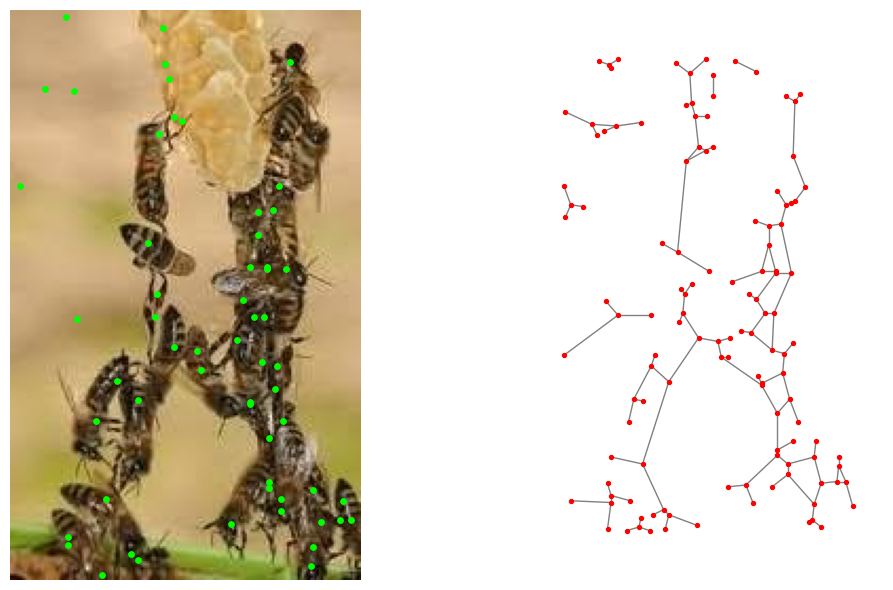

(<networkx.classes.graph.Graph at 0x18ab30d1be0>,
      skeleton-id  node-id-src  node-id-dst  branch-distance  branch-type  \
 0              0            0           18         6.242641            1   
 1              1            1           46        12.313708            1   
 2              0            2           18         6.828427            1   
 3              2            7           44        14.485281            0   
 4              1           10           46        12.485281            1   
 ..           ...          ...          ...              ...          ...   
 119            9         1415         1449         5.414214            1   
 120            4         1423         1428         2.414214            1   
 121            4         1423         1453         6.656854            1   
 122            9         1449         1463         7.828427            1   
 123            9         1449         1465         6.828427            1   
 
      mean-pixel-value  

In [2]:
analyze_bee_chains("beeFestoonImage1.jpg")


Nodes: 463, edges: 433, junctions (deg>=3): 190
Mean branch length (px): 13.875936487426582


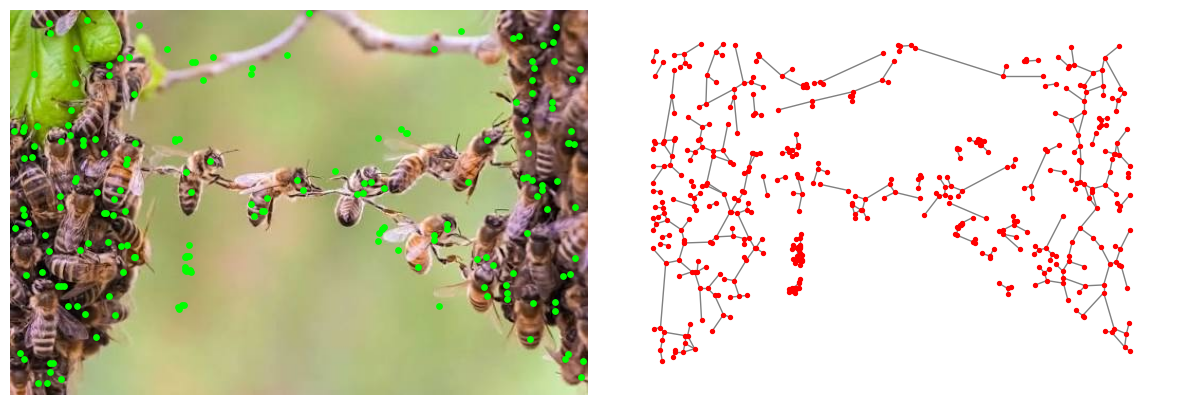

(<networkx.classes.graph.Graph at 0x18ab5970050>,
      skeleton-id  node-id-src  node-id-dst  branch-distance  branch-type  \
 0              0            0          133        26.899495            1   
 1              1            3          102        14.485281            1   
 2              1           10          788        51.798990            1   
 3              2           25           47         2.414214            1   
 4              2           31           47        14.242641            1   
 ..           ...          ...          ...              ...          ...   
 441           14         5376         5409        26.656854            2   
 442           14         5386         5445        12.828427            1   
 443           14         5388         5400         2.000000            1   
 444           14         5400         5409         9.000000            2   
 445           14         5400         5428         6.242641            1   
 
      mean-pixel-value  

In [3]:
analyze_bee_chains("beeFestoonImage2.jpg")

Nodes: 711, edges: 780, junctions (deg>=3): 417
Mean branch length (px): 16.536869684132387


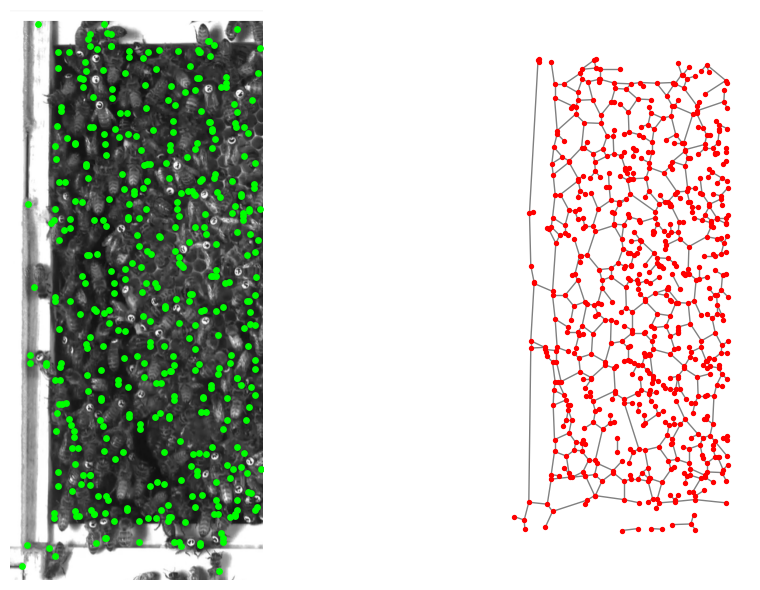

(<networkx.classes.graph.Graph at 0x18ab58e6350>,
      skeleton-id  node-id-src  node-id-dst  branch-distance  branch-type  \
 0              0            0           11         2.414214            1   
 1              0            1           24         3.414214            1   
 2              0           11         3722       247.384776            2   
 3              0           11           50         3.414214            1   
 4              0           24          195        28.313708            2   
 ..           ...          ...          ...              ...          ...   
 784            0        11322        11422        15.242641            1   
 785           14        11343        11346        32.556349            1   
 786           14        11343        11434        12.485281            1   
 787           15        11412        11435        27.071068            0   
 788           16        11413        11427        17.242641            0   
 
      mean-pixel-value  

In [4]:
analyze_bee_chains("BeeFestoonscreenshot1.png")

Nodes: 952, edges: 1032, junctions (deg>=3): 546
Mean branch length (px): 15.72052447141156


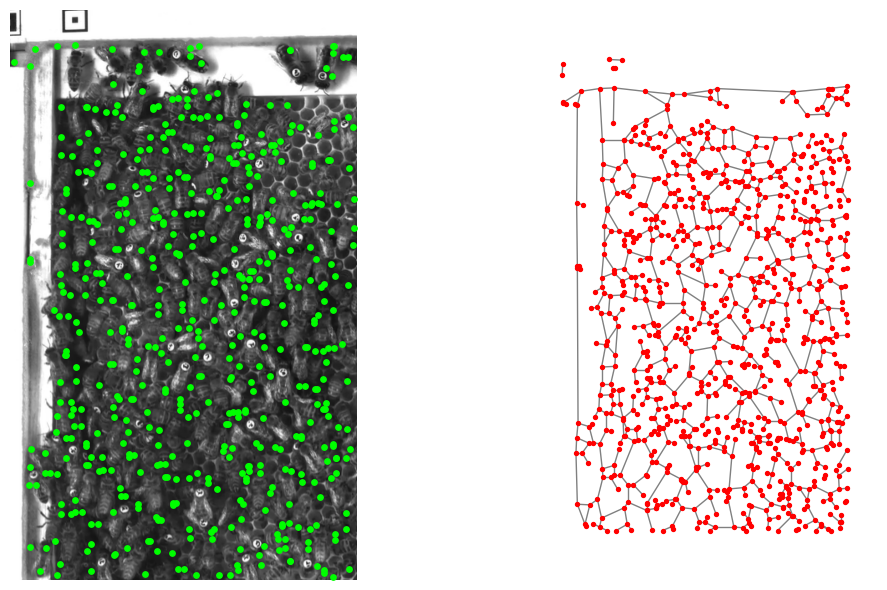

(<networkx.classes.graph.Graph at 0x18ab43d68b0>,
       skeleton-id  node-id-src  node-id-dst  branch-distance  branch-type  \
 0               0            2            5        77.142136            0   
 1               1           14           65        16.414214            0   
 2               2           34           36         2.000000            0   
 3               3          273          401        31.142136            1   
 4               3          327          375        21.414214            2   
 ...           ...          ...          ...              ...          ...   
 1037            3        14198        14231        13.414214            2   
 1038            3        14231        14320         6.242641            1   
 1039            3        14268        14268         6.242641            3   
 1040           29        14274        14291         4.414214            0   
 1041            3        14277        14326         4.828427            1   
 
       mean-

In [5]:
analyze_bee_chains("beeNotfestooning.png")

Nodes: 1091, edges: 1208, junctions (deg>=3): 648
Mean branch length (px): 16.49885889063884


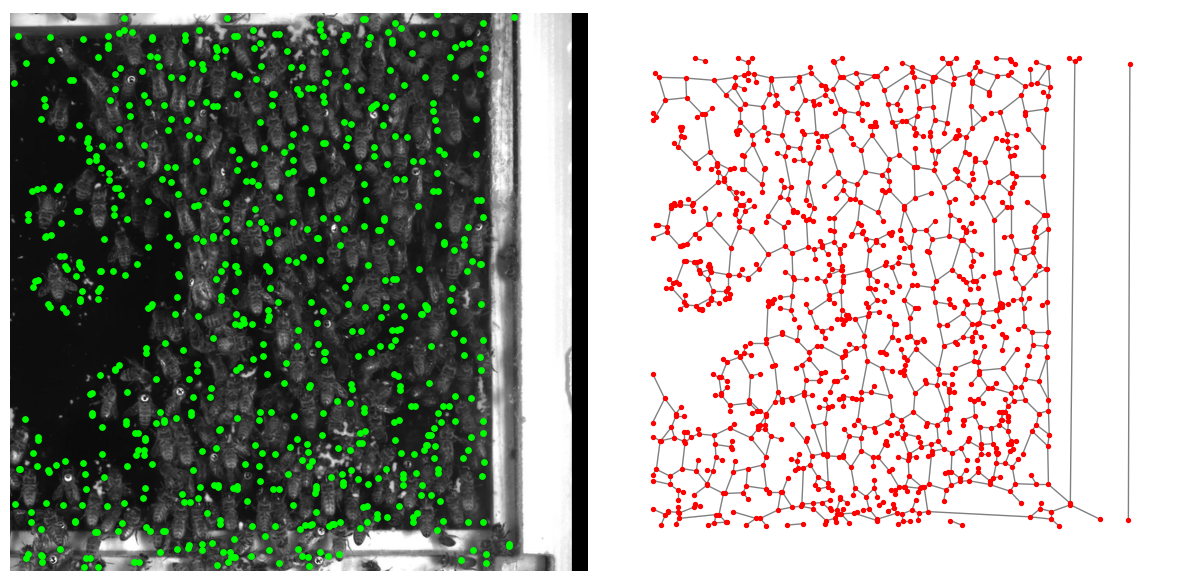

(<networkx.classes.graph.Graph at 0x18ab43d6ea0>,
       skeleton-id  node-id-src  node-id-dst  branch-distance  branch-type  \
 0               0            0           78        14.242641            0   
 1               1            1          103        15.071068            1   
 2               1            4          103         8.071068            1   
 3               1            5          106        12.071068            1   
 4               1            6          130        10.485281            1   
 ...           ...          ...          ...              ...          ...   
 1221            1        17650        17651        11.656854            1   
 1222            1        17662        17693        17.899495            2   
 1223            1        17662        17664         2.000000            1   
 1224            1        17693        17780        10.242641            1   
 1225           14        17742        17795        25.313708            0   
 
       mean-

In [6]:
analyze_bee_chains("video38beefestoonimage.png")

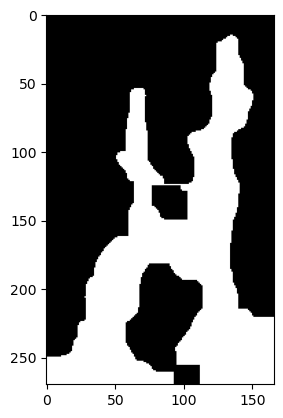

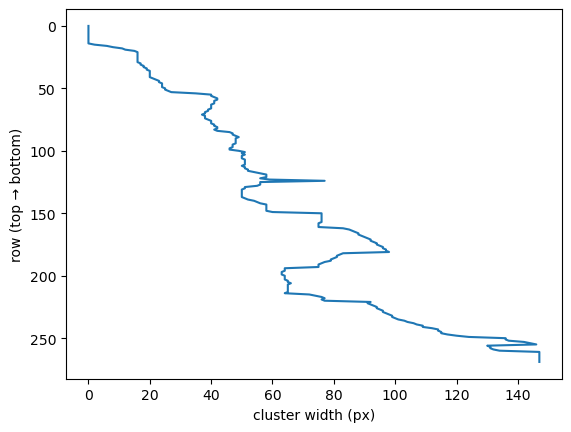

In [7]:
from skimage.morphology import remove_small_objects

img = cv2.imread("beeFestoonImage1.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (15, 15), 0)

# Otsu picks the threshold automatically; the bees are darker than the background
_, m = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# close gaps between bees, then drop specks
m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
mask = remove_small_objects(m > 0, min_size=500)

plt.imshow(mask, cmap="gray"); plt.show() 
widths = mask.sum(axis=1)
plt.plot(widths, np.arange(len(widths)))
plt.gca().invert_yaxis()
plt.xlabel("cluster width (px)"); plt.ylabel("row (top → bottom)")
plt.show()# check this first